# YOLO 번호판 자동 Annotation 생성

`test/best.pt`의 **licence** 클래스만 사용하여 `자동차번호판OCR데이터` 이미지에 번호판 박스를 생성합니다.

생성 결과:

- `자동차번호판OCR데이터/annotations/`: 원본 이미지와 같은 이름의 YOLO 라벨 `.txt`
- `자동차번호판OCR데이터/boxed_images/`: 박스를 그린 검수 이미지
- `자동차번호판OCR데이터/no_detection.txt`: 번호판을 찾지 못한 이미지 목록

각 라벨은 YOLO 학습 형식인 `class x_center y_center width height`이며 좌표는 0~1로 정규화됩니다.
번호판은 학습용 단일 클래스이므로 원본 모델의 `licence` class id를 `0`으로 재매핑합니다.

In [ ]:
# 필요한 경우 한 번만 실행하세요.
# %pip install ultralytics opencv-python tqdm

from pathlib import Path
import cv2
from tqdm.auto import tqdm
from ultralytics import YOLO

# test 폴더 또는 프로젝트 루트에서 노트북을 열어도 경로를 자동으로 찾습니다.
_roots = [Path.cwd().resolve(), Path.cwd().resolve().parent]
BASE_DIR = next(
    (p for p in _roots if (p / "test/best.pt").is_file()),
    Path.cwd().resolve(),
)
MODEL_PATH = BASE_DIR / "test" / "best.pt"
IMAGE_DIR = BASE_DIR / "자동차번호판OCR데이터"
ANNOTATION_DIR = IMAGE_DIR / "annotations"
BOXED_DIR = IMAGE_DIR / "boxed_images"
NO_DETECTION_PATH = IMAGE_DIR / "no_detection.txt"

CONFIDENCE = 0.00001
IOU_THRESHOLD =0  # NMS: 같은 번호판에 겹쳐 나온 박스를 제거하는 기준
IMAGE_SIZE = 224
BATCH_SIZE = 64
DEVICE = None  # None: 자동 선택, CPU 강제는 "cpu", 첫 GPU는 0
SAVE_BOXED_IMAGES = True
USE_ABSOLUTE_PATHS = False  # False면 프로젝트 루트 기준 상대 경로
LIMIT = None  # 빠른 시험은 20처럼 지정, 전체 생성은 None

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"YOLO 모델이 없습니다: {MODEL_PATH}")
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"이미지 폴더가 없습니다: {IMAGE_DIR}")

print("모델:", MODEL_PATH)
print("이미지 폴더:", IMAGE_DIR)

c:\Users\SSAFY\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


모델: C:\Users\SSAFY\Desktop\asdf\test\best.pt
이미지 폴더: C:\Users\SSAFY\Desktop\asdf\자동차번호판OCR데이터


## 1. 모델과 번호판 클래스 확인

In [2]:
model = YOLO(str(MODEL_PATH))
class_names = model.names
licence_ids = [
    int(class_id)
    for class_id, name in class_names.items()
    if str(name).lower() in {"licence", "license", "plate", "license_plate", "licence_plate"}
]
if not licence_ids:
    raise ValueError(f"번호판 클래스를 찾지 못했습니다. 모델 클래스: {class_names}")

LICENCE_CLASS_ID = licence_ids[0]
print("모델 클래스:", class_names)
print(f"사용할 번호판 클래스: {class_names[LICENCE_CLASS_ID]} (id={LICENCE_CLASS_ID})")
print("annotation.txt에서는 단일 클래스 id=0으로 저장합니다.")

모델 클래스: {0: 'small_trash', 1: 'standing', 2: 'sitting', 3: 'lying', 4: 'bin_overflow', 5: 'bin_normal', 6: 'bag_outside', 7: 'licence'}
사용할 번호판 클래스: licence (id=7)
annotation.txt에서는 단일 클래스 id=0으로 저장합니다.


## 2. 이미지별 annotation과 박스 이미지 생성

In [ ]:
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
if LIMIT is not None:
    image_paths = image_paths[: int(LIMIT)]
if not image_paths:
    raise RuntimeError(f"처리할 이미지가 없습니다: {IMAGE_DIR}")

BOXED_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)


def annotation_image_path(path: Path) -> str:
    selected = path.resolve() if USE_ABSOLUTE_PATHS else path.resolve().relative_to(BASE_DIR)
    # 공백이 없는 현재 데이터셋에서는 일반적인 Keras-YOLO annotation 형식과 호환됩니다.
    return selected.as_posix()


def save_unicode_image(path: Path, image) -> None:
    # 한글 경로에서도 안전하게 OpenCV 이미지를 저장합니다.
    extension = path.suffix if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"} else ".jpg"
    ok, encoded = cv2.imencode(extension, image)
    if not ok:
        raise RuntimeError(f"이미지 인코딩 실패: {path}")
    encoded.tofile(str(path))


detected_images = 0
no_detection = []
total_boxes = 0

# 작은 묶음으로 추론하여 이미지가 많아도 메모리를 과도하게 사용하지 않습니다.
for start in tqdm(range(0, len(image_paths), BATCH_SIZE), desc="YOLO annotation"):
    batch_paths = image_paths[start : start + BATCH_SIZE]
    predict_kwargs = dict(
        source=[str(p) for p in batch_paths],
        classes=[LICENCE_CLASS_ID],
        conf=CONFIDENCE,
        iou=IOU_THRESHOLD,
        imgsz=IMAGE_SIZE,
        verbose=False,
        end2end=False,
        agnostic_nms=True,
    )
    if DEVICE is not None:
        predict_kwargs["device"] = DEVICE
    results = model.predict(**predict_kwargs)

    for source_path, result in zip(batch_paths, results):
        height, width = result.orig_img.shape[:2]
        boxes = []
        if result.boxes is not None:
            for xyxy, confidence in zip(
                result.boxes.xyxy.detach().cpu().tolist(),
                result.boxes.conf.detach().cpu().tolist(),
            ):
                x1, y1, x2, y2 = xyxy
                x1 = max(0, min(width - 1, round(x1)))
                y1 = max(0, min(height - 1, round(y1)))
                x2 = max(0, min(width - 1, round(x2)))
                y2 = max(0, min(height - 1, round(y2)))
                if x2 > x1 and y2 > y1:
                    boxes.append((x1, y1, x2, y2, float(confidence)))

        if boxes:
            detected_images += 1
            total_boxes += len(boxes)
        else:
            no_detection.append(annotation_image_path(source_path))

        # 예: 01가0785.jpg -> annotations/01가0785.txt
        # 미검출 이미지도 빈 txt 파일을 만들어 이미지-라벨 쌍을 유지합니다.
        yolo_lines = []
        for x1, y1, x2, y2, _ in boxes:
            x_center = ((x1 + x2) / 2) / width
            y_center = ((y1 + y2) / 2) / height
            box_width = (x2 - x1) / width
            box_height = (y2 - y1) / height
            yolo_lines.append(
                f"0 {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}"
            )
        label_path = ANNOTATION_DIR / f"{source_path.stem}.txt"
        label_path.write_text("\n".join(yolo_lines) + ("\n" if yolo_lines else ""), encoding="utf-8")

        if SAVE_BOXED_IMAGES:
            canvas = result.orig_img.copy()
            for x1, y1, x2, y2, confidence in boxes:
                cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 255, 0), 3)
                cv2.putText(
                    canvas,
                    f"licence {confidence:.2f}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 255, 0),
                    2,
                    cv2.LINE_AA,
                )
            if not boxes:
                cv2.putText(canvas, "NO DETECTION", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            save_unicode_image(BOXED_DIR / source_path.name, canvas)

no_detection_tmp = NO_DETECTION_PATH.with_suffix(".txt.tmp")
no_detection_tmp.write_text("\n".join(no_detection) + ("\n" if no_detection else ""), encoding="utf-8")
no_detection_tmp.replace(NO_DETECTION_PATH)

print(f"처리 이미지: {len(image_paths):,}장")
print(f"번호판 검출 이미지: {detected_images:,}장")
print(f"검출 박스: {total_boxes:,}개")
print(f"미검출 이미지: {len(no_detection):,}장")
print("이미지별 annotation:", ANNOTATION_DIR)
print("박스 이미지:", BOXED_DIR)
print("미검출 목록:", NO_DETECTION_PATH)

## 3. 생성 결과 확인

이미지별 annotation 앞 5개
[01가0785.txt]
0 0.503745 0.508850 0.767790 0.592920
[01가0865.txt]
0 0.490654 0.514286 0.710280 0.438095
[01가1134-2.txt]
0 0.490234 0.461832 0.769531 0.450382
[01가1134-3.txt]
0 0.484223 0.465909 0.866505 0.693182
[01가1134-4.txt]
0 0.502513 0.480769 0.673367 0.403846
0 0.025126 0.264423 0.050251 0.125000


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_9864\24951050.py:18: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


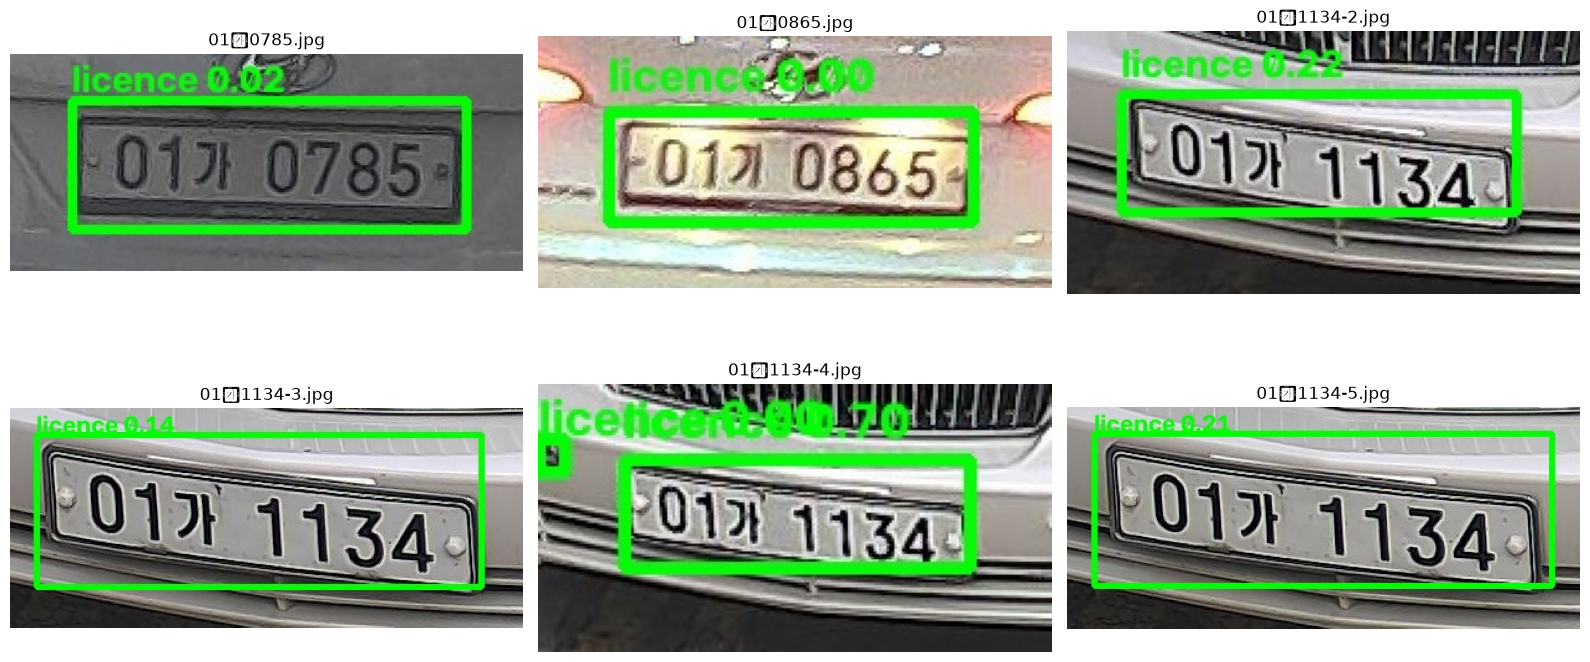

In [4]:
print("이미지별 annotation 앞 5개")
for label_path in sorted(ANNOTATION_DIR.glob("*.txt"))[:5]:
    print(f"[{label_path.name}]")
    print(label_path.read_text(encoding="utf-8").strip() or "(미검출: 빈 파일)")

# 박스 이미지 몇 장을 노트북에 표시합니다.
import matplotlib.pyplot as plt

preview_paths = [BOXED_DIR / p.name for p in image_paths[:6]]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, path in zip(axes.ravel(), preview_paths):
    image = cv2.imdecode(__import__("numpy").fromfile(str(path), dtype="uint8"), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(path.name)
    ax.axis("off")
for ax in axes.ravel()[len(preview_paths):]:
    ax.axis("off")
plt.tight_layout()
plt.show()